# Experiment 5.1: Room reverberation

This notebook compares reflection amplitudes, reflection counts, and delay spacing using the same stereo recording. Put `Am_AcusticPlug28_1.wav` beside the notebook and run the cells from top to bottom. The notebook uses the current working folder as the project folder.

Convolution and FFT are implemented manually; NumPy is used for arrays and plotting, and SciPy is used for WAV input/output.

In [6]:
from pathlib import Path
import cmath
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.io import wavfile

# Put the stereo input WAV beside this Python script.
script_dir = Path.cwd()
input_path = script_dir / "Am_AcusticPlug28_1.wav"

sample_rate, original = wavfile.read(input_path)
if original.ndim != 2 or original.shape[1] != 2:
    raise ValueError("This script expects a stereo WAV file with two channels.")

# Convert PCM integers to floating point.
if np.issubdtype(original.dtype, np.integer):
    info = np.iinfo(original.dtype)
    scale = max(abs(info.min), info.max)
    audio = original.astype(np.float32) / scale
else:
    audio = original.astype(np.float32)



C:\Users\tejas\AppData\Local\Temp\ipykernel_15108\1416132066.py:13: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sample_rate, original = wavfile.read(input_path)


## Baseline amplitude comparison

The baseline uses five reflections spaced 0.10 seconds apart. It compares amplitude patterns 2^-i and 3^-i.


## Reflection count and delay-spacing experiments

With 3^-i amplitudes held fixed, the first set changes reflection count (3, 5, or 8) while keeping 0.10-second spacing. The second set changes spacing (0.05, 0.10, or 0.20 seconds) while keeping five reflections.


In [7]:
# Reference settings for the amplitude comparison.
base_reflection_count = 5
base_delay_spacing = 0.10
base_delays = [base_delay_spacing * i for i in range(1, base_reflection_count + 1)]

# Compare two reflection-amplitude patterns: 2^-i and 3^-i.
amplitudes_2 = [2 ** (-i) for i in range(1, base_reflection_count + 1)]
amplitudes_3 = [3 ** (-i) for i in range(1, base_reflection_count + 1)]


def make_impulse_response(delays_seconds, amplitudes):
    """Build direct sound plus delayed reflection taps."""
    delay_samples = [round(delay * sample_rate) for delay in delays_seconds]
    response_length = max(delay_samples, default=0) + 1
    impulse_response = np.zeros(response_length, dtype=np.float32)
    impulse_response[0] = 1.0

    for delay, amplitude in zip(delay_samples, amplitudes):
        impulse_response[delay] += amplitude

    return impulse_response


def manual_convolve(signal, impulse_response):
    """Manually convolve one channel, skipping zero-valued impulse taps."""
    output = np.zeros(
        len(signal) + len(impulse_response) - 1,
        dtype=np.float32
    )

    for k, tap in enumerate(impulse_response):
        if tap != 0:
            for n in range(len(signal)):
                output[n + k] += signal[n] * tap

    return output


def process_stereo(impulse_response):
    """Apply the same impulse response independently to left and right."""
    return np.column_stack([
        manual_convolve(audio[:, channel], impulse_response)
        for channel in range(2)
    ])


# Amplitude experiment: five reflections at 0.10-second spacing.
impulse_response_2 = make_impulse_response(
    base_delays,
    amplitudes_2
)
impulse_response_3 = make_impulse_response(
    base_delays,
    amplitudes_3
)
processed_2 = process_stereo(impulse_response_2)
processed_3 = process_stereo(impulse_response_3)

# Reflection-count experiment: keep spacing and 3^-i amplitudes fixed.
# Delay-spacing experiment: keep the reflection count at five and use 3^-i.
experiments = [
    {
        "label": "3 reflections (0.10 s spacing)",
        "count": 3,
        "spacing": 0.10,
        "filename": "reverberated_3reflections_0.10s_3power.wav"
    },
    {
        "label": "5 reflections (0.10 s spacing)",
        "count": 5,
        "spacing": 0.10,
        "filename": "reverberated_3power.wav"
    },
    {
        "label": "8 reflections (0.10 s spacing)",
        "count": 8,
        "spacing": 0.10,
        "filename": "reverberated_8reflections_0.10s_3power.wav"
    },
    {
        "label": "5 reflections (0.05 s spacing)",
        "count": 5,
        "spacing": 0.05,
        "filename": "reverberated_5reflections_0.05s_3power.wav"
    },
    {
        "label": "5 reflections (0.20 s spacing)",
        "count": 5,
        "spacing": 0.20,
        "filename": "reverberated_5reflections_0.20s_3power.wav"
    }
]

impulse_responses = {}
processed_by_experiment = {}

for experiment in experiments:
    delays = [
        experiment["spacing"] * i
        for i in range(1, experiment["count"] + 1)
    ]
    amplitudes = [3 ** (-i) for i in range(1, experiment["count"] + 1)]
    impulse_responses[experiment["label"]] = make_impulse_response(
        delays,
        amplitudes
    )
    processed_by_experiment[experiment["label"]] = process_stereo(
        impulse_responses[experiment["label"]]
    )

# Use one shared gain if any processed output would exceed the normal range.
all_processed = [processed_2, processed_3] + list(processed_by_experiment.values())
peak = max(
    [float(np.max(np.abs(audio)))]
    + [float(np.max(np.abs(signal))) for signal in all_processed]
)
if peak > 1:
    audio = audio / peak
    processed_2 = processed_2 / peak
    processed_3 = processed_3 / peak
    for label in processed_by_experiment:
        processed_by_experiment[label] = processed_by_experiment[label] / peak

# Save the amplitude-comparison outputs.
output_2_path = script_dir / "reverberated_2power.wav"
output_3_path = script_dir / "reverberated_3power.wav"
wavfile.write(output_2_path, sample_rate, processed_2.astype(np.float32))
wavfile.write(output_3_path, sample_rate, processed_3.astype(np.float32))
print(f"Saved 2-power amplitude version: {output_2_path}")
print(f"Saved 3-power amplitude version: {output_3_path}")

# Save the outputs used to compare reflection count and delay spacing.
for experiment in experiments:
    output_path = script_dir / experiment["filename"]
    processed = processed_by_experiment[experiment["label"]]
    wavfile.write(output_path, sample_rate, processed.astype(np.float32))
    print(f"Saved {experiment['label']}: {output_path}")



Saved 2-power amplitude version: c:\Users\tejas\lssp project\reverberated_2power.wav
Saved 3-power amplitude version: c:\Users\tejas\lssp project\reverberated_3power.wav
Saved 3 reflections (0.10 s spacing): c:\Users\tejas\lssp project\reverberated_3reflections_0.10s_3power.wav
Saved 5 reflections (0.10 s spacing): c:\Users\tejas\lssp project\reverberated_3power.wav
Saved 8 reflections (0.10 s spacing): c:\Users\tejas\lssp project\reverberated_8reflections_0.10s_3power.wav
Saved 5 reflections (0.05 s spacing): c:\Users\tejas\lssp project\reverberated_5reflections_0.05s_3power.wav
Saved 5 reflections (0.20 s spacing): c:\Users\tejas\lssp project\reverberated_5reflections_0.20s_3power.wav


## Impulse response plots

The first figure compares 2-power and 3-power baseline responses. The second figure shows the count and spacing variations.

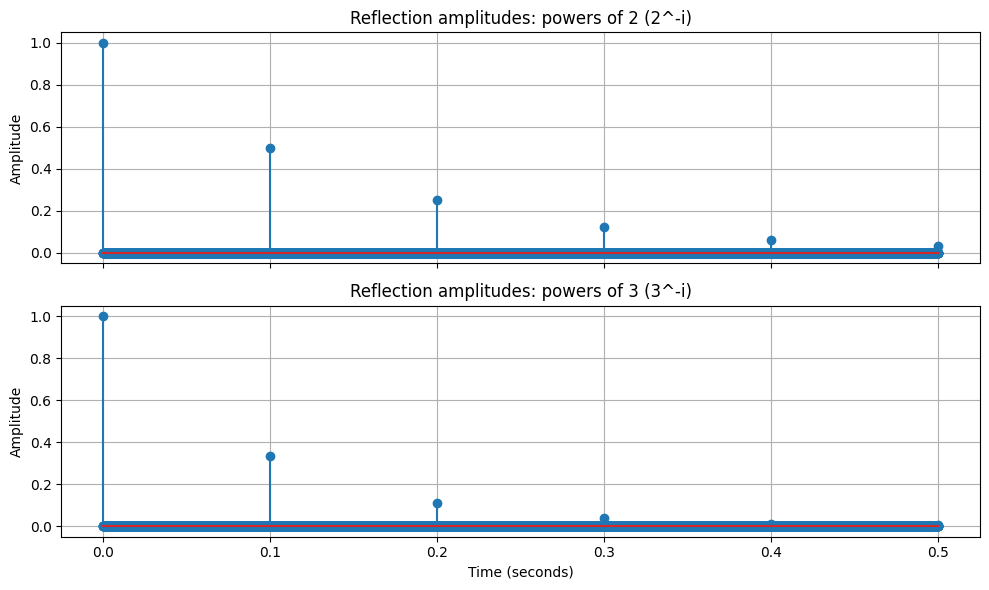

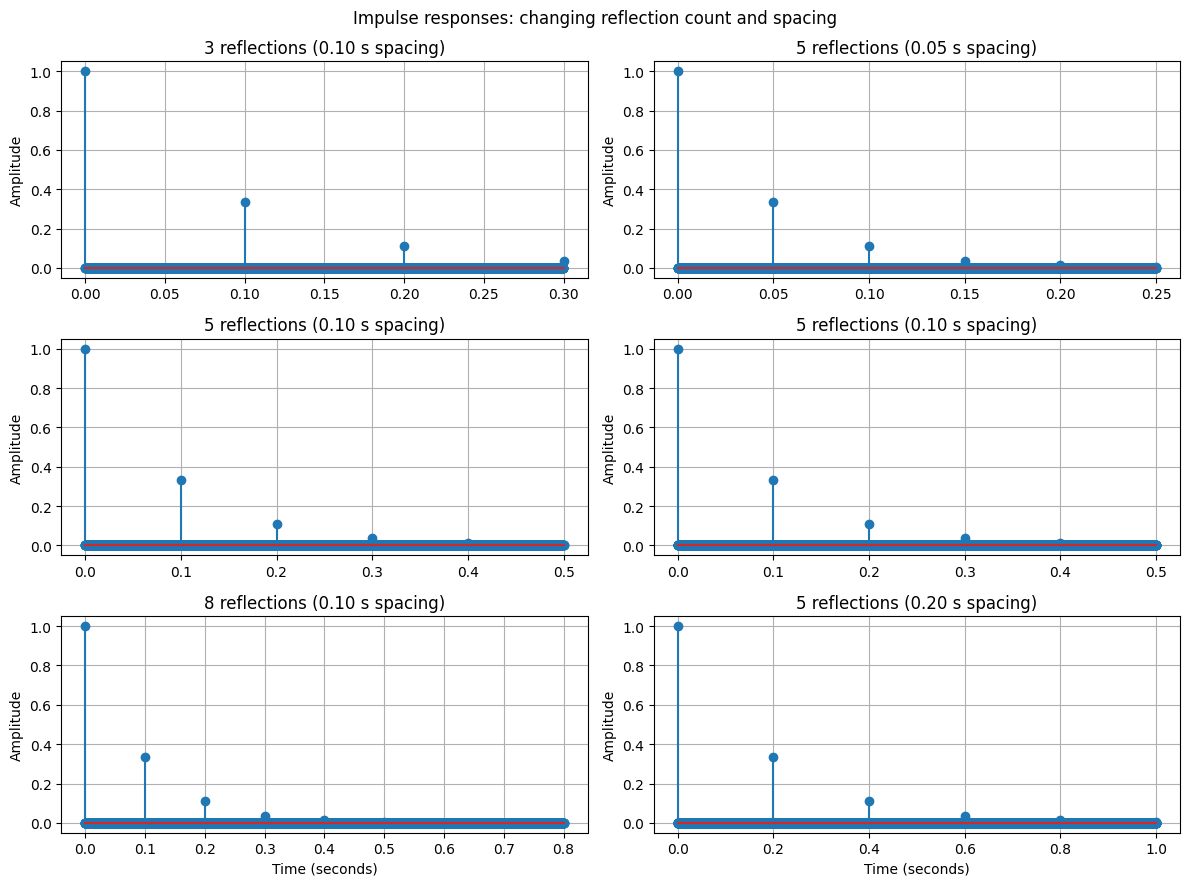

In [8]:
# Plot the two baseline impulse responses for the amplitude comparison.
base_time = np.arange(len(impulse_response_2)) / sample_rate
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].stem(base_time, impulse_response_2)
axes[0].set_title("Reflection amplitudes: powers of 2 (2^-i)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)
axes[1].stem(base_time, impulse_response_3)
axes[1].set_title("Reflection amplitudes: powers of 3 (3^-i)")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)
fig.tight_layout()

# Plot the impulse responses for the count and spacing experiments.
count_labels = [
    "3 reflections (0.10 s spacing)",
    "5 reflections (0.10 s spacing)",
    "8 reflections (0.10 s spacing)"
]
spacing_labels = [
    "5 reflections (0.05 s spacing)",
    "5 reflections (0.10 s spacing)",
    "5 reflections (0.20 s spacing)"
]
fig, axes = plt.subplots(3, 2, figsize=(12, 9))
for row, label in enumerate(count_labels):
    response = impulse_responses[label]
    time = np.arange(len(response)) / sample_rate
    axes[row, 0].stem(time, response)
    axes[row, 0].set_title(label)
    axes[row, 0].set_ylabel("Amplitude")
    axes[row, 0].grid(True)

for row, label in enumerate(spacing_labels):
    response = impulse_responses[label]
    time = np.arange(len(response)) / sample_rate
    axes[row, 1].stem(time, response)
    axes[row, 1].set_title(label)
    axes[row, 1].set_ylabel("Amplitude")
    axes[row, 1].grid(True)

axes[-1, 0].set_xlabel("Time (seconds)")
axes[-1, 1].set_xlabel("Time (seconds)")
fig.suptitle("Impulse responses: changing reflection count and spacing")
fig.tight_layout()




## Manual FFT and spectrum helper

The hand-written radix-2 Cooley-Tukey FFT is used to calculate spectra from the first five seconds of each stereo channel.

In [9]:
def fft(signal):
    """Compute the DFT recursively with the radix-2 Cooley-Tukey algorithm.

    The input is zero-padded to the next power of two before splitting.
    """
    N = len(signal)
    if N == 0:
        return []
    if N <= 1:
        return signal

    # Pad once, at the top level, so recursive halves stay powers of two.
    if N & (N - 1):
        next_pow2 = 1 << (N - 1).bit_length()
        signal = list(signal) + [0] * (next_pow2 - N)
        N = next_pow2

    even = fft(signal[0::2])
    odd = fft(signal[1::2])

    combined = [0] * N
    for k in range(N // 2):
        twiddle = cmath.exp(-2j * cmath.pi * k / N)
        combined[k] = even[k] + twiddle * odd[k]
        combined[k + N // 2] = even[k] - twiddle * odd[k]

    return combined


# Use the same first five seconds for all spectrum comparisons.
segment_samples = min(len(audio), int(5 * sample_rate))


def magnitude_spectrum(signal, channel):
    segment = signal[:segment_samples, channel]
    spectrum = fft(segment)
    fft_length = len(spectrum)
    positive_length = fft_length // 2 + 1

    frequencies = [
        k * sample_rate / fft_length
        for k in range(positive_length)
    ]
    magnitude_db = [
        20 * math.log10(max(abs(spectrum[k]), 1e-10))
        for k in range(positive_length)
    ]
    return frequencies, magnitude_db

## Spectrum comparisons

The plots compare amplitude patterns, reflection counts, and delay spacings for left and right channels.

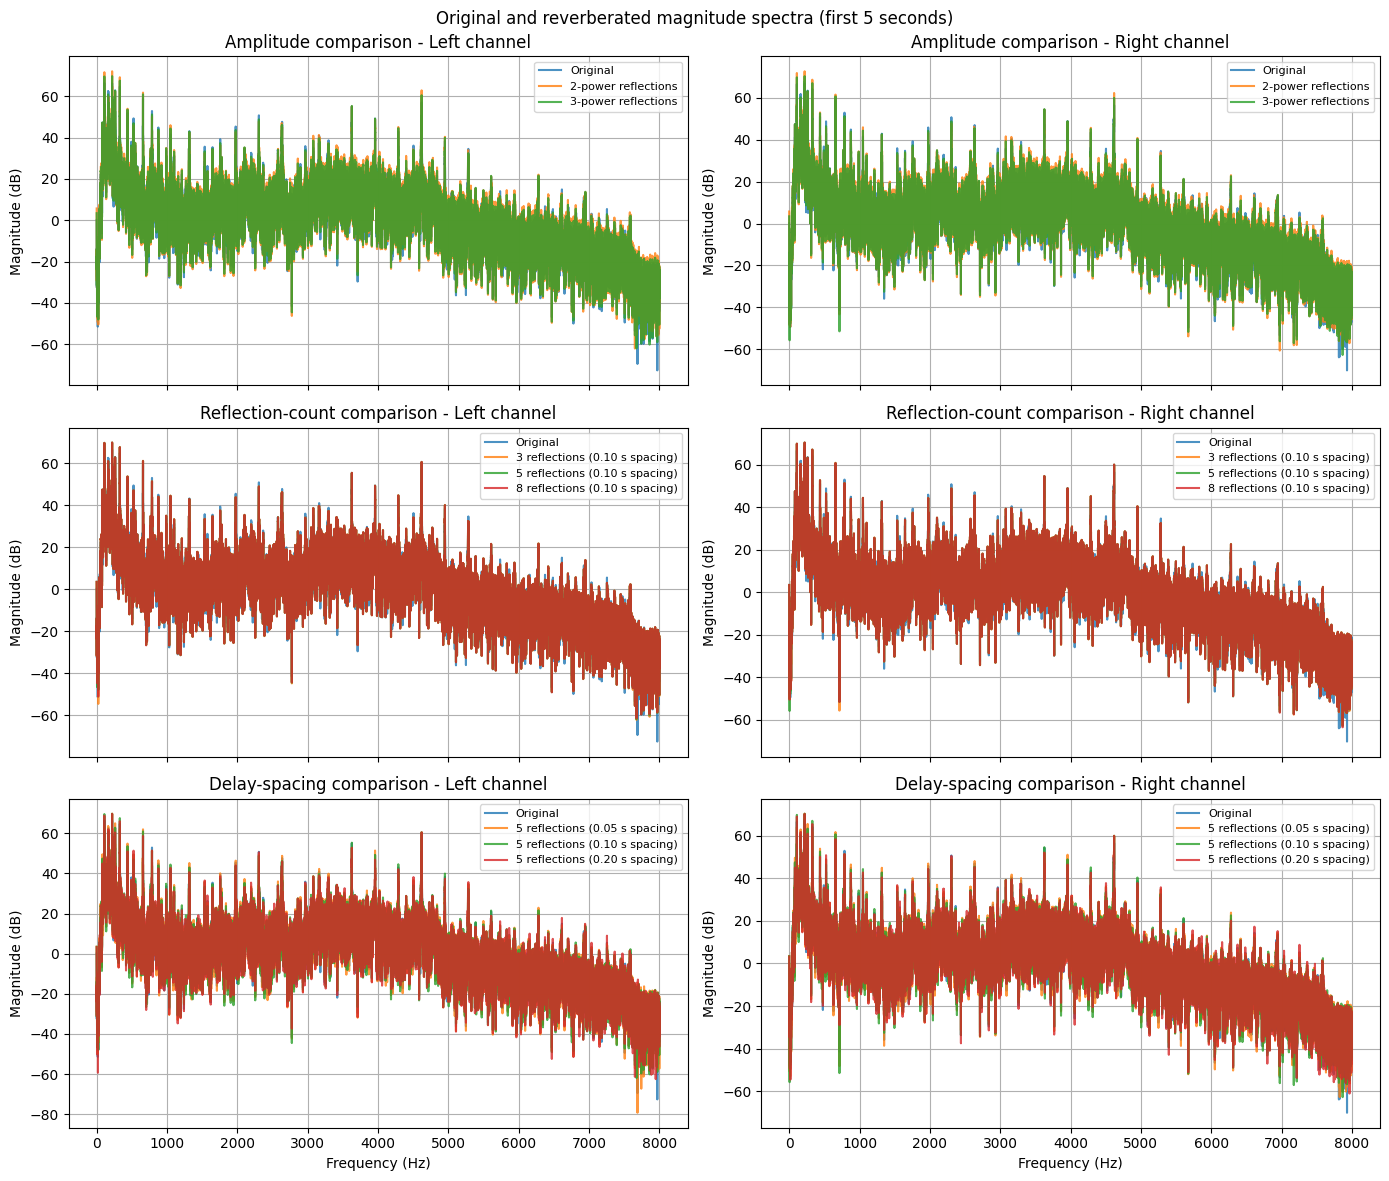

In [10]:
# Compare amplitude, reflection-count, and delay-spacing experiments.
# The same first five seconds are used for every signal and both channels.
fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True)
for channel, channel_name in enumerate(["Left", "Right"]):
    axis = axes[0, channel]
    f_original, mag_original = magnitude_spectrum(audio, channel)
    f_2, mag_2 = magnitude_spectrum(processed_2, channel)
    f_3, mag_3 = magnitude_spectrum(processed_3, channel)
    axis.plot(f_original, mag_original, label="Original", alpha=0.8)
    axis.plot(f_2, mag_2, label="2-power reflections", alpha=0.8)
    axis.plot(f_3, mag_3, label="3-power reflections", alpha=0.8)
    axis.set_title(f"Amplitude comparison - {channel_name} channel")
    axis.set_ylabel("Magnitude (dB)")
    axis.legend(fontsize=8)
    axis.grid(True)

    axis = axes[1, channel]
    axis.plot(f_original, mag_original, label="Original", alpha=0.8)
    for label in count_labels:
        frequencies, magnitude_db = magnitude_spectrum(
            processed_by_experiment[label],
            channel
        )
        axis.plot(frequencies, magnitude_db, label=label, alpha=0.8)
    axis.set_title(f"Reflection-count comparison - {channel_name} channel")
    axis.set_ylabel("Magnitude (dB)")
    axis.legend(fontsize=8)
    axis.grid(True)

    axis = axes[2, channel]
    axis.plot(f_original, mag_original, label="Original", alpha=0.8)
    for label in spacing_labels:
        frequencies, magnitude_db = magnitude_spectrum(
            processed_by_experiment[label],
            channel
        )
        axis.plot(frequencies, magnitude_db, label=label, alpha=0.8)
    axis.set_title(f"Delay-spacing comparison - {channel_name} channel")
    axis.set_ylabel("Magnitude (dB)")
    axis.legend(fontsize=8)
    axis.grid(True)

axes[-1, 0].set_xlabel("Frequency (Hz)")
axes[-1, 1].set_xlabel("Frequency (Hz)")
fig.suptitle("Original and reverberated magnitude spectra (first 5 seconds)")
fig.tight_layout()
plt.show()
